## Task 4: Video Motion Estimation

### Aim
To detect and estimate motion in a video using computer vision techniques.

### Methods
- **Frame Differencing:** Detects changes between consecutive video frames.
- **Background Subtraction:** Separates moving objects from a relatively stationary background.
- **Lucas–Kanade Optical Flow:** Estimates the movement of selected image features between frames.

The methods will be visualized and compared using a self-recorded video.

Video loaded successfully.
Resolution: 1080 x 1920
Frames: 159
FPS: 29.92
Duration (seconds): 5.31


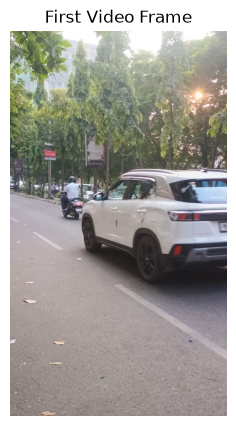

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path(r"D:\Computer Vision Project")
INPUT_DIR = PROJECT_DIR / "input"
OUTPUT_DIR = PROJECT_DIR / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

VIDEO_PATH = INPUT_DIR / "motion_video.mp4"

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise FileNotFoundError(
        f"Could not open video: {VIDEO_PATH}"
    )

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print("Video loaded successfully.")
print("Resolution:", width, "x", height)
print("Frames:", frame_count)
print("FPS:", round(fps, 2))
print("Duration (seconds):", round(frame_count / fps, 2) if fps > 0 else "Unknown")

ret, first_frame = cap.read()

if ret:
    plt.figure(figsize=(8, 5))
    plt.imshow(cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB))
    plt.title("First Video Frame")
    plt.axis("off")
    plt.show()

cap.release()

## 2. Frame Differencing

Frame differencing detects motion by comparing consecutive grayscale frames. A threshold is applied to the difference image to highlight regions where movement occurs.

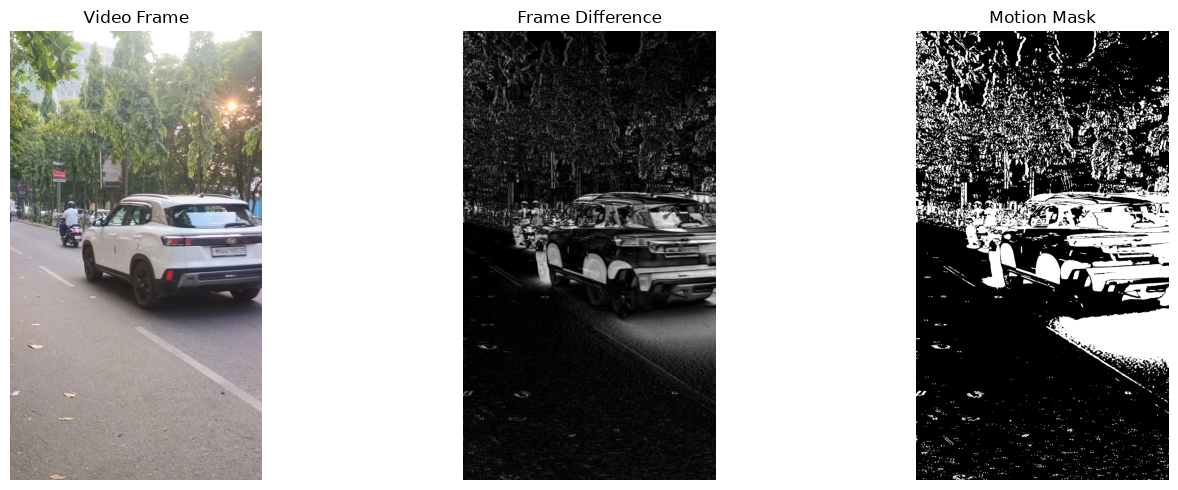

Saved frame difference results.


In [2]:
cap = cv2.VideoCapture(str(VIDEO_PATH))

ret, previous_frame = cap.read()

if not ret:
    cap.release()
    raise RuntimeError("Could not read the first video frame.")

previous_gray = cv2.cvtColor(previous_frame, cv2.COLOR_BGR2GRAY)
previous_gray = cv2.GaussianBlur(previous_gray, (5, 5), 0)

# Process a later frame
for _ in range(5):
    ret, current_frame = cap.read()
    if not ret:
        break

if not ret:
    cap.release()
    raise RuntimeError("The video is too short to compare frames.")

current_gray = cv2.cvtColor(current_frame, cv2.COLOR_BGR2GRAY)
current_gray = cv2.GaussianBlur(current_gray, (5, 5), 0)

# Calculate frame difference
difference = cv2.absdiff(previous_gray, current_gray)

# Threshold the difference to identify motion
_, motion_mask = cv2.threshold(
    difference, 25, 255, cv2.THRESH_BINARY
)

# Save the results
cv2.imwrite(str(OUTPUT_DIR / "frame_difference.png"), difference)
cv2.imwrite(str(OUTPUT_DIR / "frame_difference_mask.png"), motion_mask)

# Display the results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(cv2.cvtColor(current_frame, cv2.COLOR_BGR2RGB))
axes[0].set_title("Video Frame")
axes[0].axis("off")

axes[1].imshow(difference, cmap="gray")
axes[1].set_title("Frame Difference")
axes[1].axis("off")

axes[2].imshow(motion_mask, cmap="gray")
axes[2].set_title("Motion Mask")
axes[2].axis("off")

plt.tight_layout()
plt.show()

cap.release()

print("Saved frame difference results.")

### Observation

The difference image highlights pixel changes between frames. The binary motion mask separates significant changes from smaller intensity variations. Background movement and lighting changes may also appear as motion.

## 3. GMM Background Subtraction

Background subtraction separates moving foreground objects from a relatively stationary background. OpenCV's MOG2 method models background changes using a Gaussian Mixture Model.

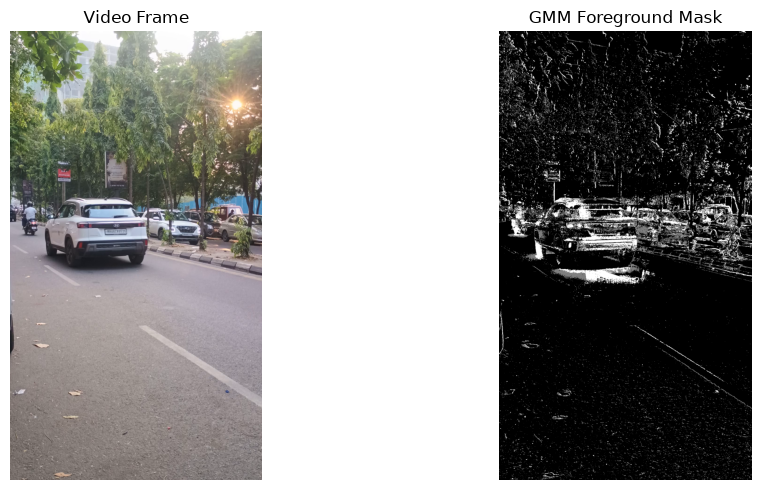

Processed frames: 159
Saved GMM output: D:\Computer Vision Project\outputs\gmm_background_subtraction.mp4


In [3]:
cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError("Could not open the video.")

# Create the GMM-based background subtractor
background_subtractor = cv2.createBackgroundSubtractorMOG2(
    history=500,
    varThreshold=25,
    detectShadows=True
)

# Prepare an output video
output_path = OUTPUT_DIR / "gmm_background_subtraction.mp4"
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
fps = cap.get(cv2.CAP_PROP_FPS)

if fps <= 0:
    fps = 25.0

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

writer = cv2.VideoWriter(
    str(output_path), fourcc, fps, (width, height)
)

sample_frame = None
sample_mask = None
frame_number = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break

    foreground_mask = background_subtractor.apply(frame)

    # Save a representative result from around the middle
    if frame_number == 30:
        sample_frame = frame.copy()
        sample_mask = foreground_mask.copy()

    # Convert the mask to a colour image for video output
    mask_colour = cv2.cvtColor(
        foreground_mask, cv2.COLOR_GRAY2BGR
    )

    writer.write(mask_colour)
    frame_number += 1

cap.release()
writer.release()

if sample_frame is not None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(cv2.cvtColor(sample_frame, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Video Frame")
    axes[0].axis("off")

    axes[1].imshow(sample_mask, cmap="gray")
    axes[1].set_title("GMM Foreground Mask")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    cv2.imwrite(
        str(OUTPUT_DIR / "gmm_foreground_mask.png"),
        sample_mask
    )
else:
    print("The video contains fewer than 31 frames.")

print("Processed frames:", frame_number)
print("Saved GMM output:", output_path)

### Observation

The foreground mask highlights regions that differ from the learned background. Shadows, lighting changes, and objects that remain still may affect the result. The model generally improves as it observes more frames.

## 4. Lucas–Kanade Optical Flow

The Lucas–Kanade method estimates motion by tracking selected feature points between consecutive video frames. Motion vectors indicate the direction and approximate displacement of these points.

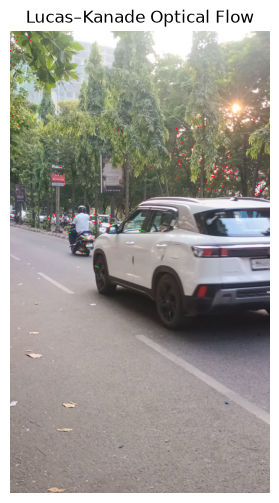

Feature points detected: 100
Points successfully tracked: 100
Saved: outputs/lucas_kanade_optical_flow.png


In [4]:
cap = cv2.VideoCapture(str(VIDEO_PATH))

ret, old_frame = cap.read()

if not ret:
    cap.release()
    raise RuntimeError("Could not read the video.")

old_gray = cv2.cvtColor(old_frame, cv2.COLOR_BGR2GRAY)

# Detect feature points to track
feature_params = dict(
    maxCorners=100,
    qualityLevel=0.3,
    minDistance=7,
    blockSize=7
)

old_points = cv2.goodFeaturesToTrack(
    old_gray, mask=None, **feature_params
)

if old_points is None:
    cap.release()
    raise RuntimeError(
        "No suitable feature points found in the first frame."
    )

# Lucas-Kanade optical flow settings
lk_params = dict(
    winSize=(15, 15),
    maxLevel=2,
    criteria=(
        cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT,
        10,
        0.03
    )
)

ret, new_frame = cap.read()

if not ret:
    cap.release()
    raise RuntimeError("The video needs at least two frames.")

new_gray = cv2.cvtColor(new_frame, cv2.COLOR_BGR2GRAY)

new_points, status, errors = cv2.calcOpticalFlowPyrLK(
    old_gray, new_gray, old_points, None, **lk_params
)

if new_points is None or status is None:
    cap.release()
    raise RuntimeError("Optical flow could not track feature points.")

# Keep successfully tracked points
good_new = new_points[status.ravel() == 1]
good_old = old_points[status.ravel() == 1]

# Draw motion vectors
flow_result = new_frame.copy()

for new, old in zip(good_new, good_old):
    x_new, y_new = new.ravel().astype(int)
    x_old, y_old = old.ravel().astype(int)

    cv2.arrowedLine(
        flow_result,
        (x_old, y_old),
        (x_new, y_new),
        (0, 255, 0),
        2,
        tipLength=0.3
    )

    cv2.circle(
        flow_result, (x_new, y_new), 3, (0, 0, 255), -1
    )

# Display and save
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(flow_result, cv2.COLOR_BGR2RGB))
plt.title("Lucas–Kanade Optical Flow")
plt.axis("off")
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "lucas_kanade_optical_flow.png"),
    flow_result
)

cap.release()

print("Feature points detected:", len(old_points))
print("Points successfully tracked:", len(good_new))
print("Saved: outputs/lucas_kanade_optical_flow.png")

### Observation

Green arrows represent the estimated movement of tracked feature points between frames. The number and quality of tracked points depend on image texture, lighting, and the amount of motion between frames.

## 5. Comparison of Motion Estimation Methods

The three methods detect motion in different ways:

- **Frame Differencing:** Detects pixel changes between consecutive frames.
- **GMM Background Subtraction:** Separates foreground regions from a learned background.
- **Lucas–Kanade Optical Flow:** Estimates the movement of tracked feature points.

Their performance depends on the scene, lighting, camera stability, and object movement.

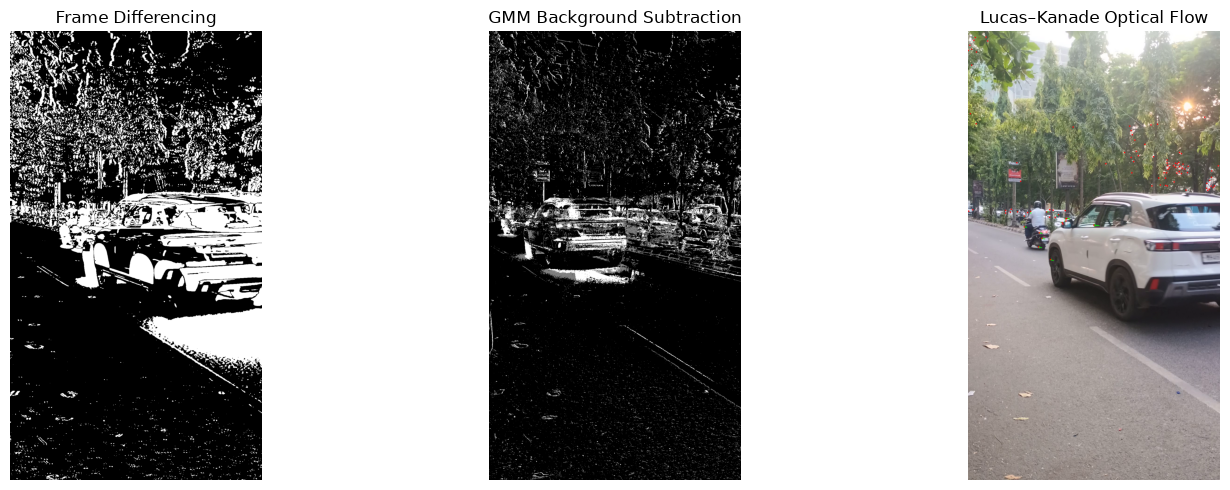

In [5]:
frame_diff_path = OUTPUT_DIR / "frame_difference_mask.png"
gmm_path = OUTPUT_DIR / "gmm_foreground_mask.png"
flow_path = OUTPUT_DIR / "lucas_kanade_optical_flow.png"

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Frame differencing
if frame_diff_path.exists():
    img = cv2.imread(str(frame_diff_path), cv2.IMREAD_GRAYSCALE)
    axes[0].imshow(img, cmap="gray")
    axes[0].set_title("Frame Differencing")
else:
    axes[0].text(0.5, 0.5, "Output not found", ha="center", va="center")

axes[0].axis("off")

# GMM
if gmm_path.exists():
    img = cv2.imread(str(gmm_path), cv2.IMREAD_GRAYSCALE)
    axes[1].imshow(img, cmap="gray")
    axes[1].set_title("GMM Background Subtraction")
else:
    axes[1].text(0.5, 0.5, "Output not found", ha="center", va="center")

axes[1].axis("off")

# Optical flow
if flow_path.exists():
    img = cv2.imread(str(flow_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[2].imshow(img)
    axes[2].set_title("Lucas–Kanade Optical Flow")
else:
    axes[2].text(0.5, 0.5, "Output not found", ha="center", va="center")

axes[2].axis("off")

plt.tight_layout()
plt.show()